In [14]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth, fpmax
import random

In [15]:
df = pd.read_csv('coffee_shop_transactions.csv')
print(df.shape)
df.head(5)

(1000, 19)


,TransactionID,Latte,Hazelnut Latte,Vanilla Latte,Creamy Aren Latte,Caramel Latte,Matcha Latte,Cappuccino,Caramel Macchiato,Americano,Matcha Bun,Cheese Toast,Chocolate Toast,Butter Toast,Cookies,Croissant,Egg Salad Toast,Fries,Crispy Chicken Nuggets
0,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,1,0,0,0
1,2,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,1
2,3,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,0
3,4,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0
4,5,0,0,1,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0


In [16]:
df = df.drop(columns=['TransactionID'], errors='ignore').copy()
df = df.astype(bool)
df

,Latte,Hazelnut Latte,Vanilla Latte,Creamy Aren Latte,Caramel Latte,Matcha Latte,Cappuccino,Caramel Macchiato,Americano,Matcha Bun,Cheese Toast,Chocolate Toast,Butter Toast,Cookies,Croissant,Egg Salad Toast,Fries,Crispy Chicken Nuggets
0,False,False,True,False,True,False,False,True,False,True,False,False,False,False,True,False,False,False
1,False,False,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,True
2,False,False,False,False,True,False,False,False,True,True,False,False,False,False,True,False,False,False
3,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,False,False
4,False,False,True,False,False,True,False,True,True,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,False,False,True,False,False,False,True,True,False,False,False,False,False,False,True,False,False,True
996,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False
997,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
998,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,True


In [17]:
frequent_itemsets = fpgrowth(
    df,
    min_support=0.025,
    use_colnames=True
)
frequent_itemsets.sort_values(by='support', ascending=False)

frequent_itemsets = fpmax(
    df,
    min_support=0.025,
    use_colnames=True
)
frequent_itemsets.sort_values(by='support', ascending=False)

,support,itemsets
47,0.039,"(Creamy Aren Latte, Hazelnut Latte)"
63,0.035,"(Chocolate Toast, Egg Salad Toast)"
72,0.034,"(Fries, Americano)"
46,0.034,"(Creamy Aren Latte, Fries)"
79,0.034,"(Cheese Toast, Caramel Macchiato)"
...,...,...
41,0.025,"(Cappuccino, Creamy Aren Latte)"
58,0.025,"(Fries, Egg Salad Toast)"
57,0.025,"(Caramel Macchiato, Egg Salad Toast)"
59,0.025,"(Egg Salad Toast, Americano)"


In [18]:
frequent_itemsets = apriori(
    df,
    min_support=0.025,
    use_colnames=True
)
frequent_itemsets.sort_values(by='support', ascending=False)

,support,itemsets
14,0.176,(Croissant)
16,0.175,(Fries)
1,0.173,(Hazelnut Latte)
7,0.173,(Caramel Macchiato)
10,0.173,(Cheese Toast)
...,...,...
47,0.025,"(Matcha Latte, Caramel Latte)"
81,0.025,"(Egg Salad Toast, Americano)"
75,0.025,"(Caramel Macchiato, Egg Salad Toast)"
76,0.025,"(Matcha Bun, Americano)"


In [19]:
rules = association_rules(
    frequent_itemsets,
    metric='lift',
    min_threshold=1.2,
    num_itemsets=len(frequent_itemsets)
)

print(len(rules))

10


In [20]:
print("\n" + "="*50)
print("АНАЛИЗ ПОЛУЧЕННЫХ РЕЗУЛЬТАТОВ")
print("="*50)

# Фильтруем правила с высокой достоверностью
strong_rules = rules[(rules['confidence'] > 0.2) & (rules['lift'] > 1.2)]
print(f"\nСильные правила (confidence > 0.2 lift > 1.2): {len(strong_rules)}")

if len(strong_rules) > 0:
    print("\nПримеры сильных правил:")
    for idx, row in strong_rules.head().iterrows():
        antecedents = ', '.join(list(row['antecedents']))
        consequents = ', '.join(list(row['consequents']))
        print(f"\nПравило: [{antecedents}] -> [{consequents}]")
        print(f"  Поддержка (support): {row['support']:.3f} - правило встречается в {row['support']*100:.1f}% транзакций")
        print(f"  Достоверность (confidence): {row['confidence']:.3f} - при покупке {antecedents} в {row['confidence']*100:.1f}% случаев покупают {consequents}")
        print(f"  Lift: {row['lift']:.3f} - покупка {antecedents} увеличивает вероятность покупки {consequents} в {row['lift']:.2f} раз")


АНАЛИЗ ПОЛУЧЕННЫХ РЕЗУЛЬТАТОВ

Сильные правила (confidence > 0.2 lift > 1.2): 5

Примеры сильных правил:

Правило: [Latte] -> [Matcha Latte]
  Поддержка (support): 0.032 - правило встречается в 3.2% транзакций
  Достоверность (confidence): 0.232 - при покупке Latte в 23.2% случаев покупают Matcha Latte
  Lift: 1.372 - покупка Latte увеличивает вероятность покупки Matcha Latte в 1.37 раз

Правило: [Creamy Aren Latte] -> [Hazelnut Latte]
  Поддержка (support): 0.039 - правило встречается в 3.9% транзакций
  Достоверность (confidence): 0.238 - при покупке Creamy Aren Latte в 23.8% случаев покупают Hazelnut Latte
  Lift: 1.375 - покупка Creamy Aren Latte увеличивает вероятность покупки Hazelnut Latte в 1.37 раз

Правило: [Hazelnut Latte] -> [Creamy Aren Latte]
  Поддержка (support): 0.039 - правило встречается в 3.9% транзакций
  Достоверность (confidence): 0.225 - при покупке Hazelnut Latte в 22.5% случаев покупают Creamy Aren Latte
  Lift: 1.375 - покупка Hazelnut Latte увеличивает веро

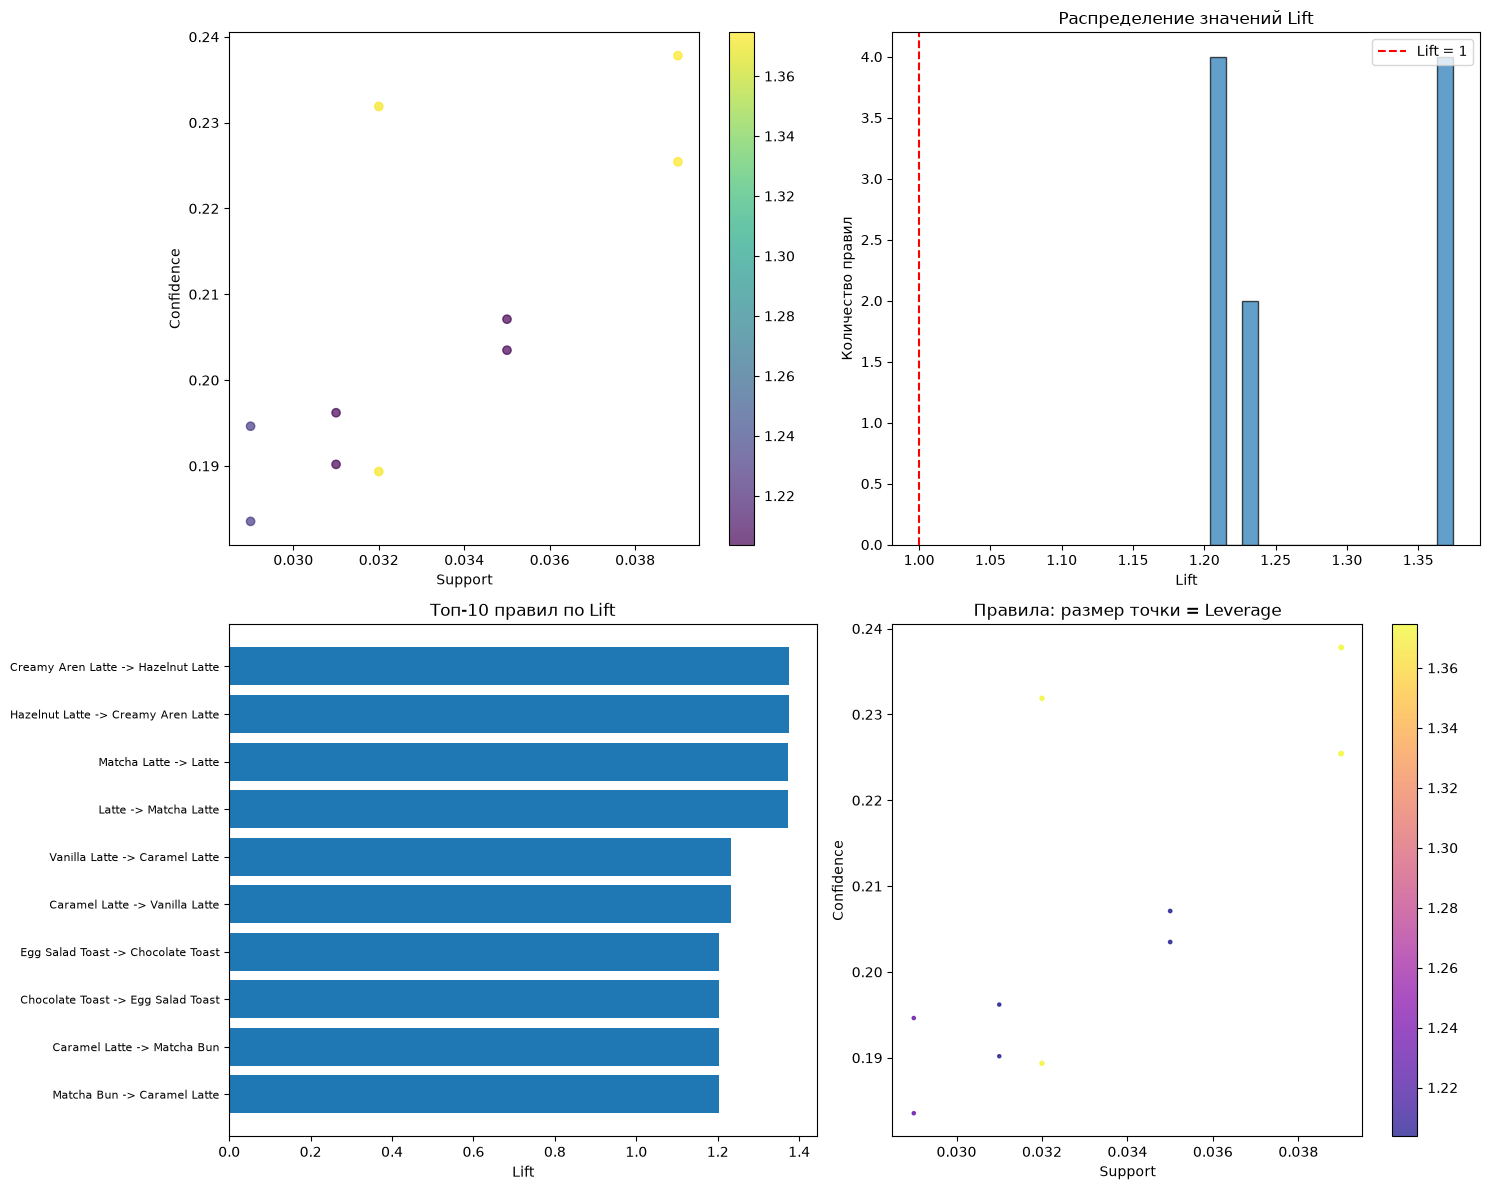

In [21]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns


fig, axes = plt.subplots(2, 2, figsize=(15, 12))

scatter = axes[0, 0].scatter(
    rules['support'], rules['confidence'],
    c=rules['lift'], cmap='viridis', alpha=0.7
)
axes[0, 0].set_xlabel('Support')
axes[0, 0].set_ylabel('Confidence')
plt.colorbar(scatter, ax=axes[0, 0])

axes[0, 1].hist(rules['lift'], bins=15, edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Lift')
axes[0, 1].set_ylabel('Количество правил')
axes[0, 1].set_title('Распределение значений Lift')
axes[0, 1].axvline(x=1, color='red', linestyle='--', label='Lift = 1')
axes[0, 1].legend()

top_rules = rules.nlargest(10, 'lift').copy()
y_pos = range(len(top_rules))
rule_labels = [
    f"{', '.join(sorted(list(a)))} -> {', '.join(sorted(list(c)))}"
    for a, c in zip(top_rules['antecedents'], top_rules['consequents'])
]
axes[1, 0].barh(y_pos, top_rules['lift'])
axes[1, 0].set_yticks(list(y_pos))
axes[1, 0].set_yticklabels(rule_labels, fontsize=8)
axes[1, 0].set_xlabel('Lift')
axes[1, 0].set_title('Топ-10 правил по Lift')
axes[1, 0].invert_yaxis()

scatter2 = axes[1, 1].scatter(
    rules['support'], rules['confidence'],
    c=rules['lift'], s=rules['leverage'] * 1000,
    cmap='plasma', alpha=0.7
)
axes[1, 1].set_xlabel('Support')
axes[1, 1].set_ylabel('Confidence')
axes[1, 1].set_title('Правила: размер точки = Leverage')
plt.colorbar(scatter2, ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [22]:
# Сохраняем результаты в CSV файлы
frequent_itemsets.to_csv('frequent_itemsets.csv', index=False)
rules.to_csv('association_rules.csv', index=False)

print("\nРезультаты сохранены в файлы:")
print("- frequent_itemsets.csv (частые наборы)")
print("- association_rules.csv (ассоциативные правила)")

# Выводим основную статистику
print("\n" + "="*50)
print("ИТОГОВАЯ СТАТИСТИКА")
print("="*50)
print(f"Всего транзакций: {len(df)}")
print(f"Уникальных товаров: {len(df.columns)}")
print(f"Частых наборов найдено: {len(frequent_itemsets)}")
print(f"Ассоциативных правил сгенерировано: {len(rules)}")
print(f"Средняя поддержка правил: {rules['support'].mean():.3f}")
print(f"Средняя достоверность: {rules['confidence'].mean():.3f}")
print(f"Средний lift: {rules['lift'].mean():.3f}")


Результаты сохранены в файлы:
- frequent_itemsets.csv (частые наборы)
- association_rules.csv (ассоциативные правила)

ИТОГОВАЯ СТАТИСТИКА
Всего транзакций: 1000
Уникальных товаров: 18
Частых наборов найдено: 103
Ассоциативных правил сгенерировано: 10
Средняя поддержка правил: 0.033
Средняя достоверность: 0.206
Средний lift: 1.277
